In [11]:
import osmnx as ox
import networkx as nx
import r5py as r
from matplotlib import pyplot as plt

import pandas as pd
import geopandas as gpd
import shapely

pd.set_option("display.max_columns", None)

descargar el polígono del area de interés

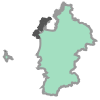

In [40]:
place_name = "Provincia de Concepción, Chile"
# place_name = "Concepción, Chile"-

# geocode_to_gdf descarga el gdf con geometría en lon, lat (EPGS:4326)
area_gdf = ox.geocode_to_gdf(place_name)

area = area_gdf.geometry.iloc[0]
area

descargar el pbf de chile y guardarlo en network/ con el siguiente comando
```bash
cd network
wget https://download.geofabrik.de/south-america/chile-latest.osm.pbf
```

In [41]:
import pyrosm

# ruta de tu archivo local de Chile descargado
fp = "network/chile-latest.osm.pbf"

# pyrosm acepta tu polígono (4326) directamente para filtrar el PBF de forma eficiente
osm = pyrosm.OSM(fp, bounding_box=area)

# extraer la red de conducción (driving) junto con sus nodos
nodes, edges = osm.get_network(network_type="driving", nodes=True)

# realizar un recorte (clip) geométrico exacto con tu polígono 
# para eliminar cualquier tramo que sobresalga del límite provincial

# cortar usando el spatial index de geopandas
match_indices = edges.sindex.query(area, predicate="intersects")
edges = edges.iloc[match_indices]

# filtrar únicamente los nodos que pertenecen a las aristas recortadas
node_ids = set(edges['u']).union(set(edges['v']))
nodes = nodes[nodes['id'].isin(node_ids)]

# nodes.lon = nodes.geometry.x
# nodes.lat = nodes.geometry.y

# renombrar lon, lat a x, y
nodes = nodes.rename(columns={'lon': 'x', 'lat': 'y'})

# convertirlo a un grafo G de networkx
G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

print(f"done\n{len(G.nodes):,} nodes\n{len(G.edges):,} edges")

done
34,295 nodes
84,311 edges


In [42]:
G = osm.to_graph(nodes, edges, graph_type="networkx", simplify=True)

In [43]:
# guardar grafo
ox.save_graph_geopackage(G, f"network/{"_".join(place_name.lower().split(",")[0].split(" "))}.gpkg", encoding="latin-1")

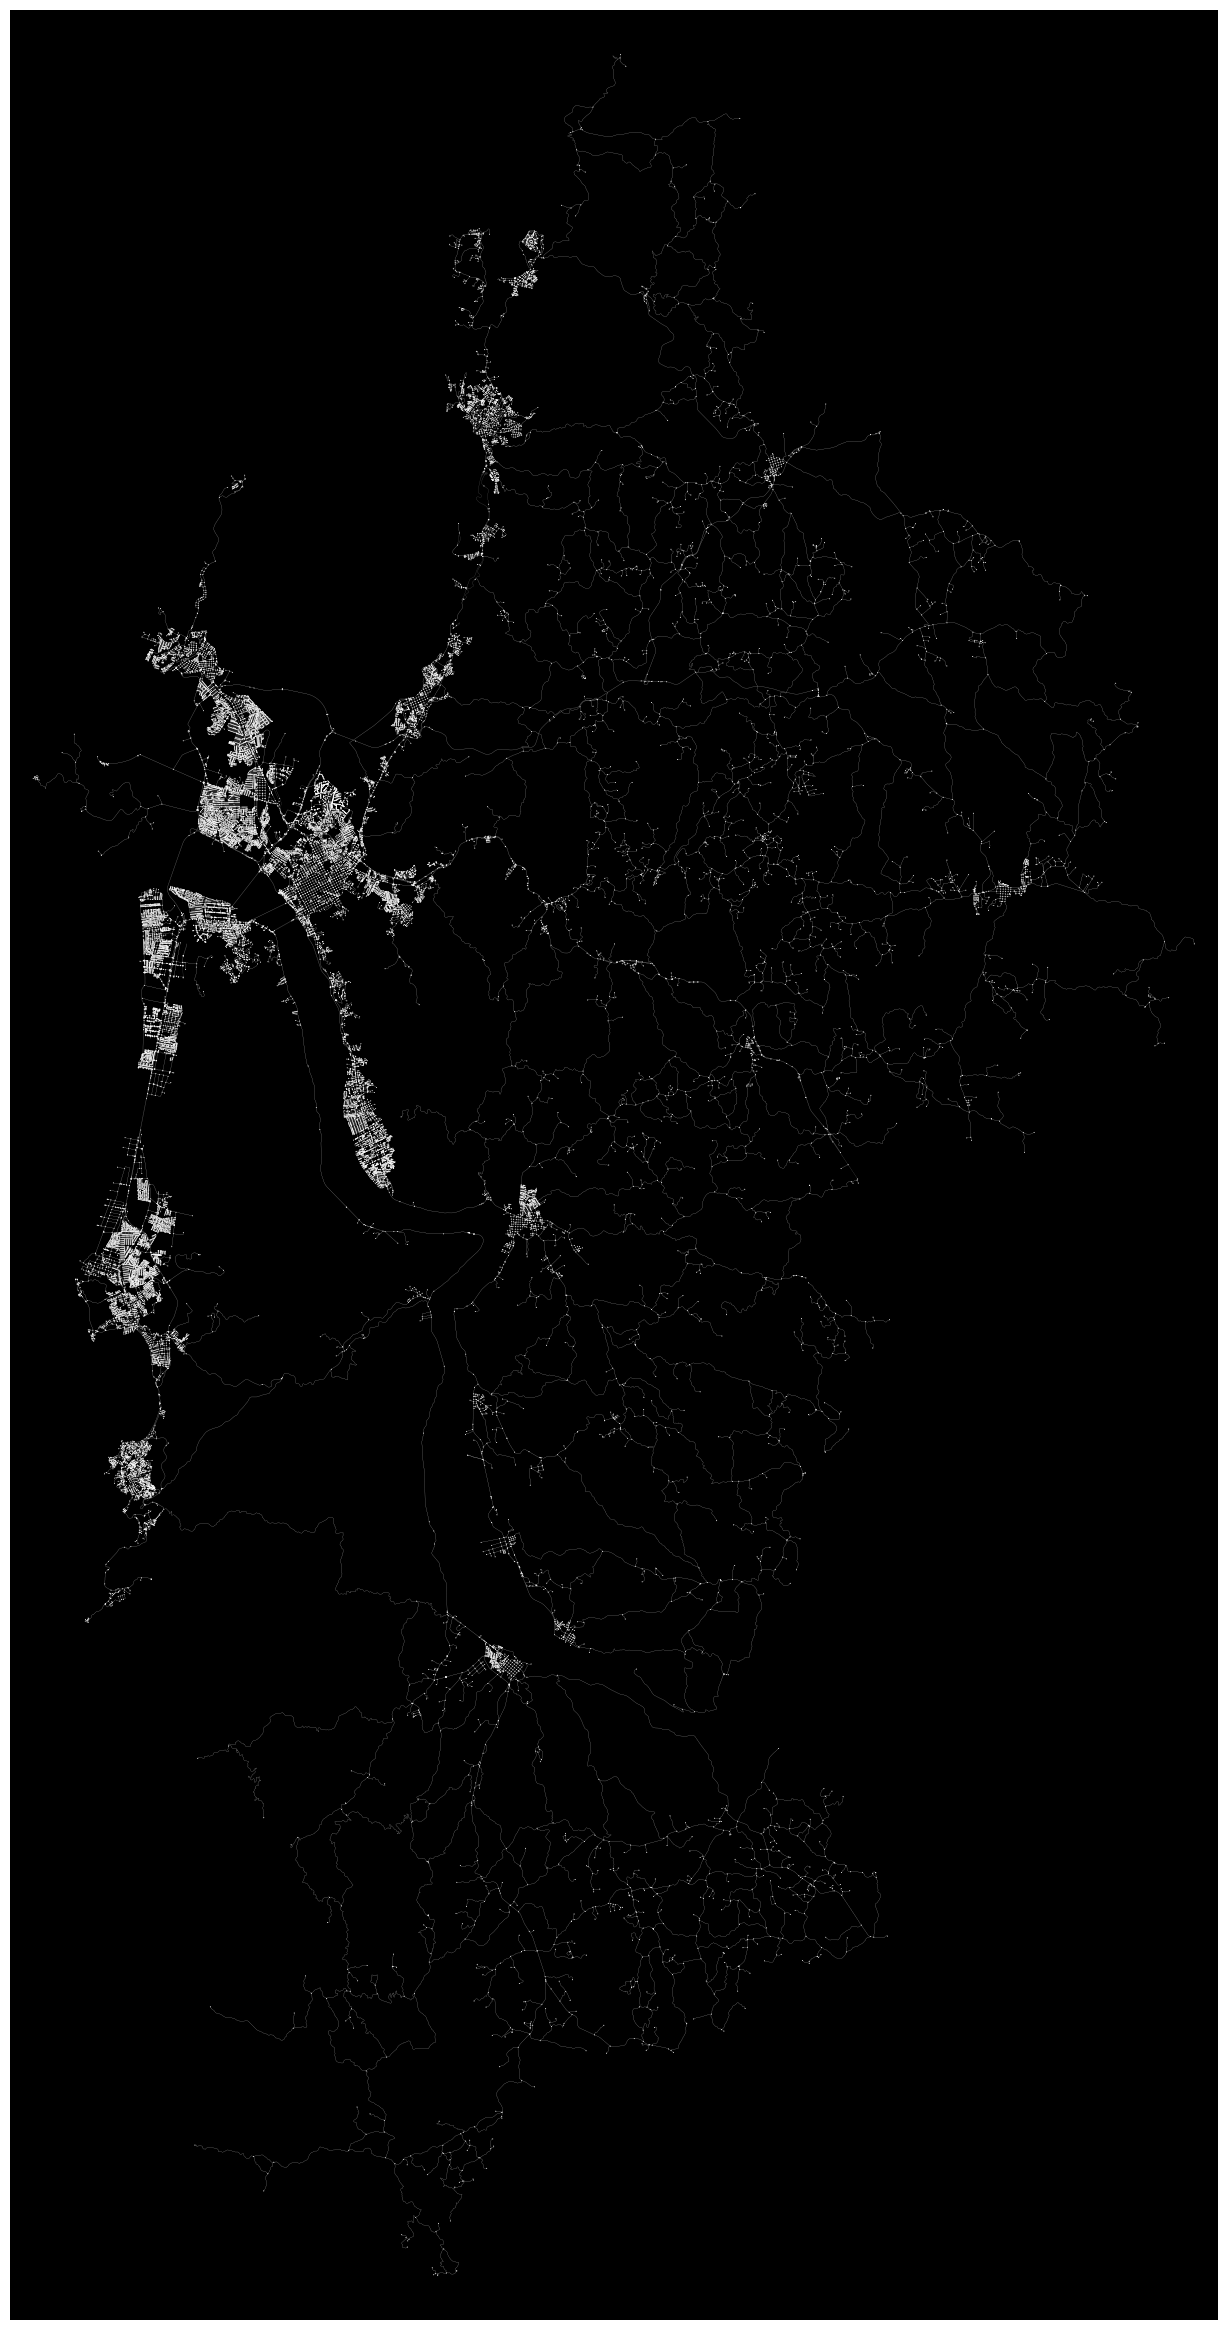

(<Figure size 3000x3000 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [44]:
# dibujar grafo
ox.plot_graph(G, figsize=(30,30), edge_linewidth=0.1, node_size=0.5, node_color="white", bgcolor="black")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

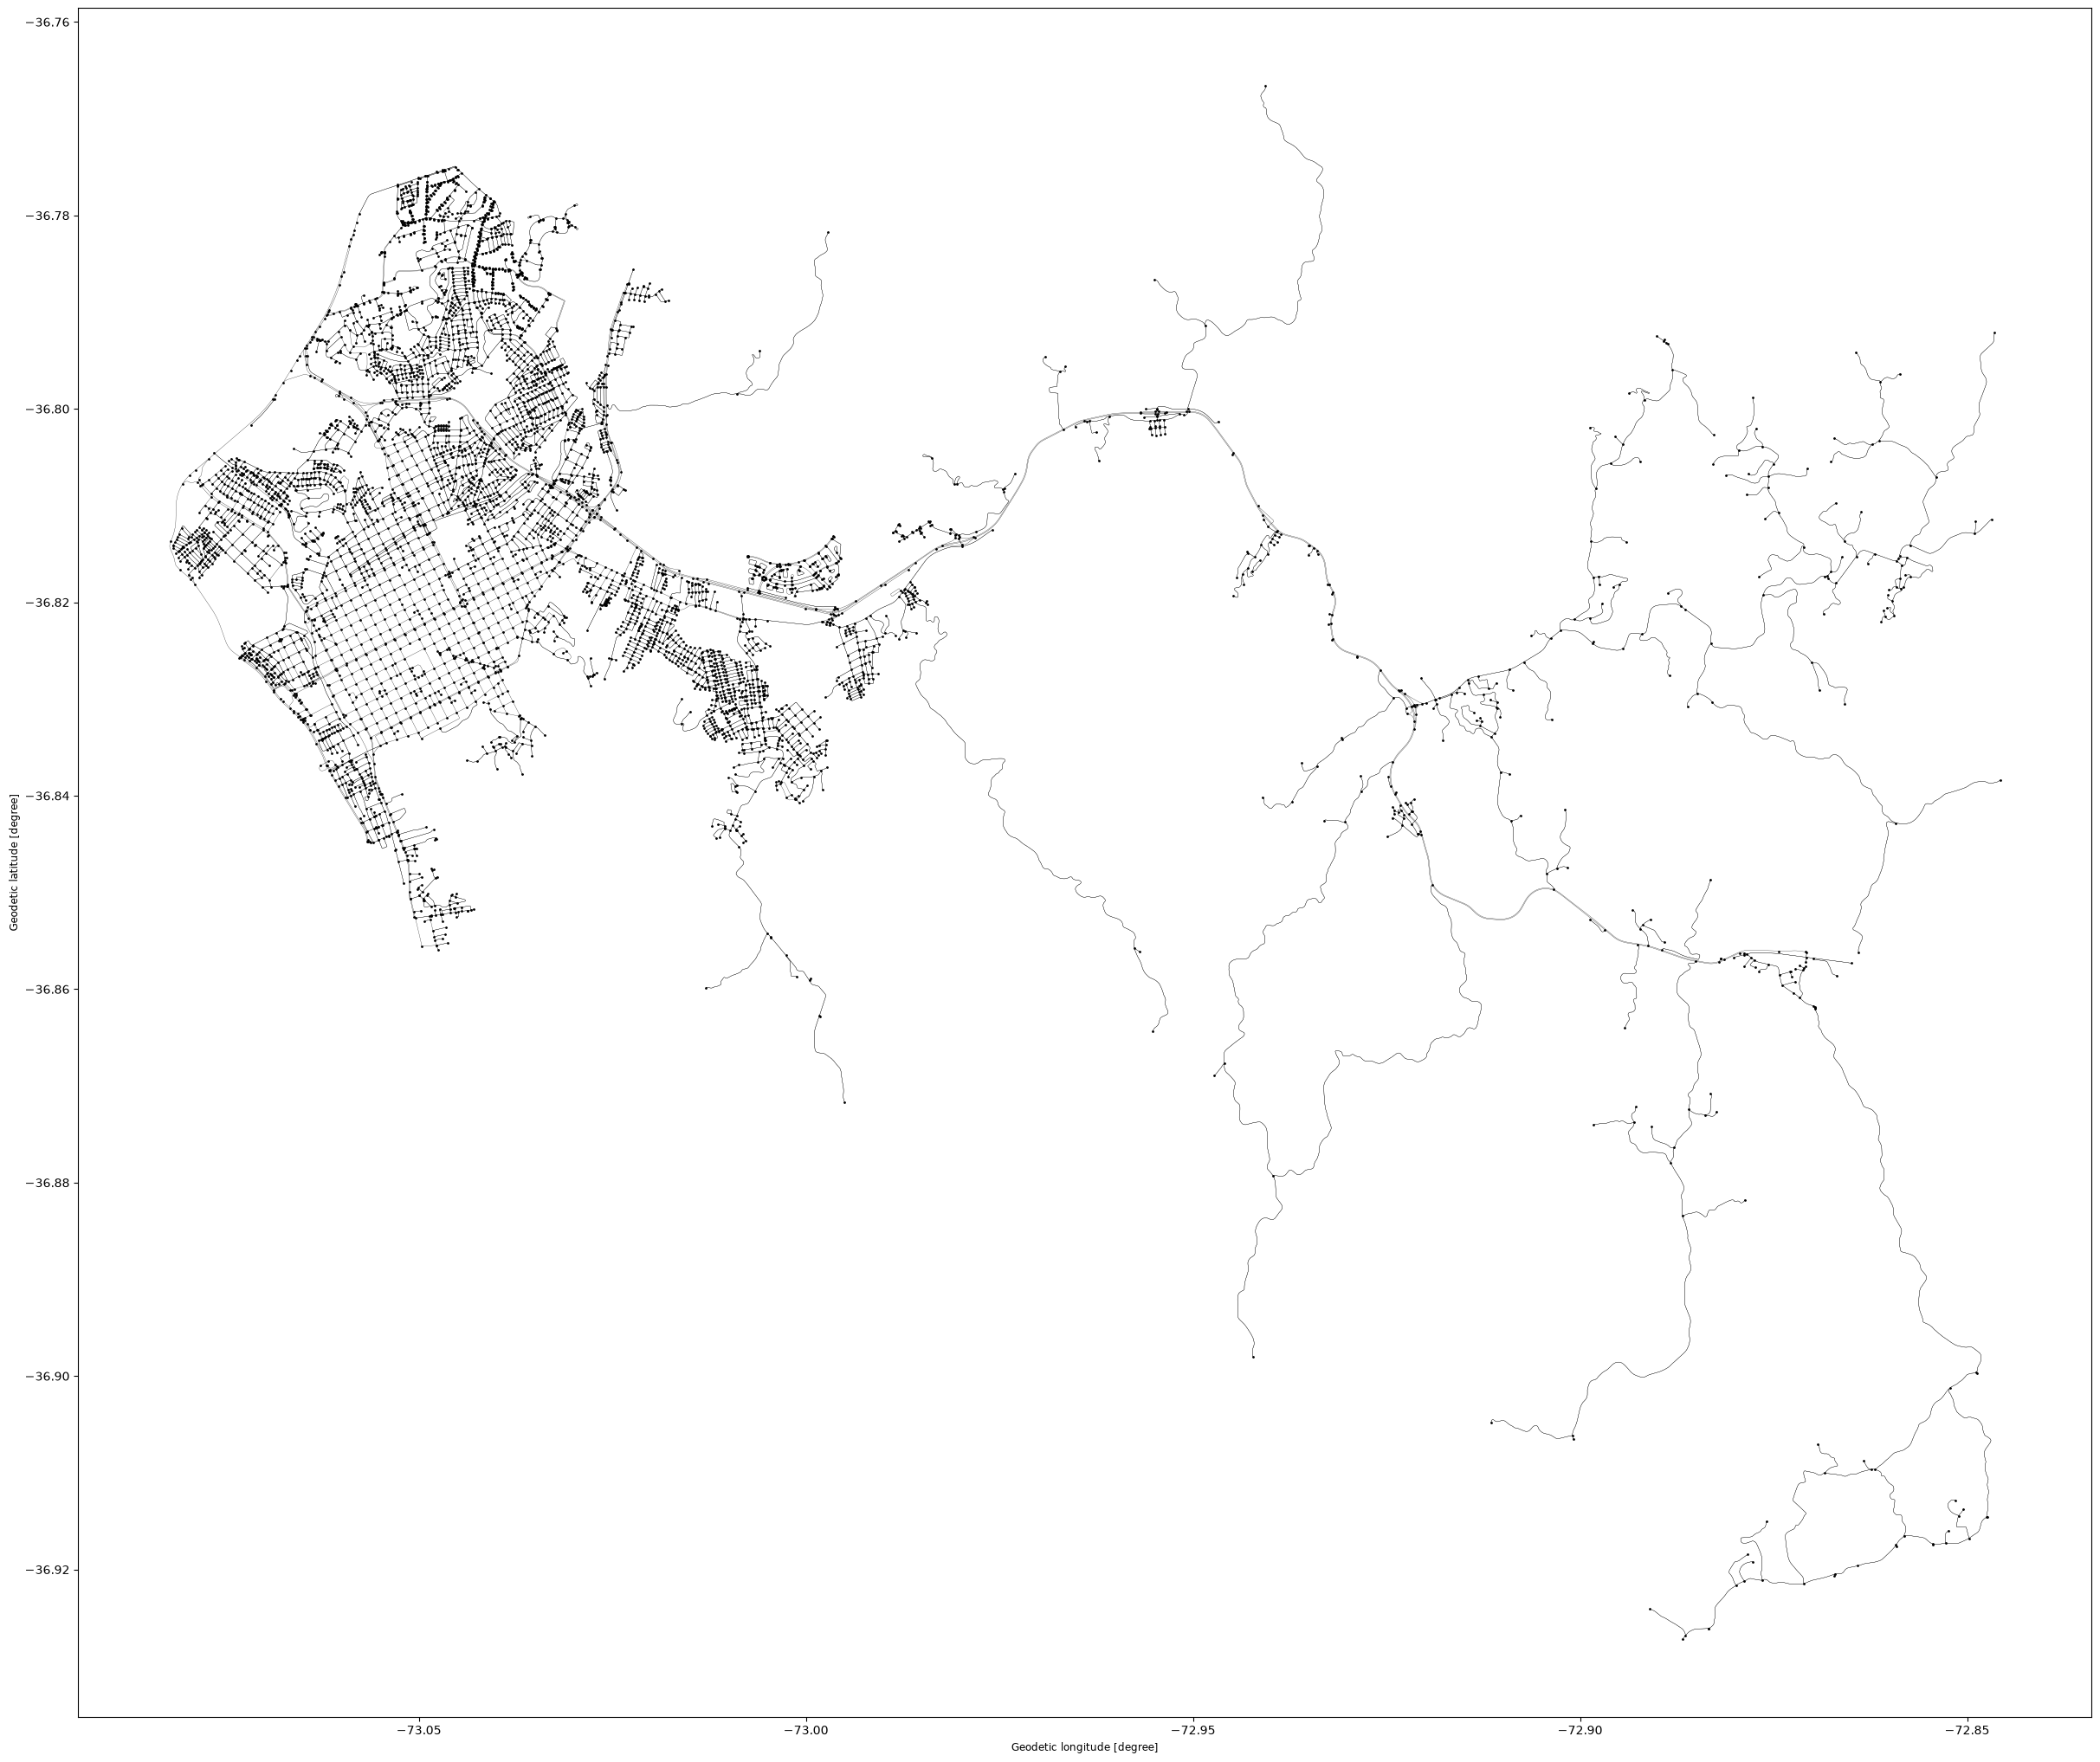

In [38]:
# reobtener los gdf edges y nodes del grafo simplificado
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

# dibujar los gdf independientemente
ax = edges_gdf.plot(figsize=(30,30), linewidth=0.2, color="black", legend=True)
nodes_gdf.plot(ax=ax, markersize=1, color="black")